Data Analytics (DA)
Module-End -5
Module End  Assignment: Python For Data Analysis
###Social Media Engagement Analytics

Assignment Tasks:


###Task 1 — Data Import & Setup
Import CSV using Pandas
Check/convert data types
Convert date columns to datetime
Use NumPy arrays for basic array operations:

Imported pandas as pd and numpy as np
for data manipulation and basic numerical operations and array handling respectively.

Imported the csv file using the file upload function from local file manager. Used ".head()" to display the first five rows of the dataset.

".info()" identified the datatypes and non-null count  of the columns individually.

Identified and converted the wrong datatypes of the columns into right ones:

AGE: Converted the datatype FLOAT64 to INTEGER64(Filled the missing age using median).

LIKES,COMMENTS,SHARES: Converted the datatype FLOAT64 to INTEGER64(Filled the missing values using median).

POSTED_AT: Converted the datatype OBJECT into DATETIME using "datetime()"

Verified the changes using ".dtype()"






In [2]:
import pandas as pd
import numpy as np

from google.colab import files
uploaded=files.upload()

df=pd.read_csv('social_media_engagement_5000.csv')
df.head()




Saving social_media_engagement_5000.csv to social_media_engagement_5000.csv


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   object 
 3   country           5000 non-null   object 
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   object 
 6   post_category     5000 non-null   object 
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   object 
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   object 
 16  sentiment         4850 non-null   object 


In [4]:
#Changing datatype of age column
df["age"]=df["age"].fillna(df["age"].median())
df["age"]=df["age"].astype("int64")

#Changing datatype of likes,comments,shares columns
df["likes"]=df["likes"].fillna(df["likes"].median())
df["likes"]=df["likes"].astype("int64")

df["comments"]=df["comments"].fillna(df["comments"].median())
df["comments"]=df["comments"].astype("int64")

df["shares"]=df["shares"].fillna(df["shares"].median())
df["shares"]=df["shares"].astype("int64")



df["posted_at"]=pd.to_datetime(df["posted_at"])
df.info()

df.dtypes







<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   int64         
 2   gender            4850 non-null   object        
 3   country           5000 non-null   object        
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   object        
 6   post_category     5000 non-null   object        
 7   likes             5000 non-null   int64         
 8   comments          5000 non-null   int64         
 9   shares            5000 non-null   int64         
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[ns]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 n

/tmp/ipykernel_722/2731192262.py:17: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["posted_at"]=pd.to_datetime(df["posted_at"])


,0
user_id,int64
age,int64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,int64
comments,int64
shares,int64


###Task 2 — Data Cleaning
####Cleaning Missing Data
Detect missing values (isnull(), isna()):
Used the ".info()" to identify the missing values in the dataset.Missing values were found in age,gender,likes,comments,shares,sentiment columns.The missing values in the age,likes,comments,shares were replaced using the median value to maintain the numerical consistency.



Handle using: dropna(), fillna(), median/mode, forward/backward-fill:
Missing values in the gender column were replaced using MODE imputation.Missing values in the sentiment column were handled and replaced using FORWARDFILL(ffill), which replaces the missing values with the preceeding available value.


####Duplicate Handling
Identify & remove duplicates:No duplicate records were found (using duplicated()).

####Data Formatting
Fix incorrect data types: Already completed under TASK 1.

Standardize categories (e.g., gender labels): Inspected using "value_counts()", no further standardisation was required as the category was consistent.(3 categories Male,Female and Others were found totalling to 5000)

Correct unrealistic values in likes, comments, shares:Examined the statistical summary of the three columns.Observed no unrealistic values.


####Feature Cleaning

Extract hashtag count: Used "explode()" to seperate multiple hashtags within a cell, "value_count()" to calculate the occurences of each hashtags.

Clean sentiment labels: Identified the missing values, by using forward fill(ffill()), replaced the missing  values.


In [5]:
#Filling missing gender values
df["gender"]=df["gender"].fillna(df["gender"].mode()[0])
df["sentiment"]=df["sentiment"].fillna(method="ffill")
df.info()




<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   int64         
 2   gender            5000 non-null   object        
 3   country           5000 non-null   object        
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   object        
 6   post_category     5000 non-null   object        
 7   likes             5000 non-null   int64         
 8   comments          5000 non-null   int64         
 9   shares            5000 non-null   int64         
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[ns]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 n

/tmp/ipykernel_722/4190074556.py:3: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df["sentiment"]=df["sentiment"].fillna(method="ffill")


In [6]:
#check for duplicates
df.duplicated().sum()

np.int64(0)

In [7]:
#check gender categories
df["gender"].value_counts()




,count
gender,
Male,1849
Other,1581
Female,1570


In [8]:
#check unrealistic values in likes,comments and shares
df[["likes","comments","shares"]].describe()

,likes,comments,shares
count,5000.000000,5000.000000,5000.0000
mean,10106.982400,1502.039800,1002.9106
std,5702.293022,856.393312,570.8552
min,10.000000,0.000000,0.0000
25%,5235.000000,792.000000,511.0000
50%,10105.000000,1497.000000,1012.0000
75%,14959.000000,2235.250000,1483.0000
max,19998.000000,2999.000000,1999.0000


In [9]:
#Extracting hashtag count
hashtags_count=(df["hashtags"].str.findall(r"#\w+")).explode().value_counts()
print(hashtags_count)








hashtags
#tech         1045
#foodie       1037
#lifestyle    1024
#reels        1007
#fashion      1006
#fun          1005
#music         984
#fitness       978
#love          972
#travel        935
Name: count, dtype: int64


In [10]:
#Clean sentiment labels
df["sentiment"].value_counts()


,count
sentiment,
positive,2434
neutral,1575
negative,991


###Data transformation

####Standardising categorical text values:

".str.strip()" remove leading and trailing spaces

".str.capitalize()" makes the first letter uppercase







In [11]:
#Standardising categorical text values
col=["post_type","post_category","device_type","sentiment"]
for col in col:
  df[col]=df[col].str.strip().str.capitalize()
df[["post_type","post_category","device_type","sentiment"]].head()

,post_type,post_category,device_type,sentiment
0,Image,Fitness,Mobile,Negative
1,Reel,Food,Mobile,Negative
2,Text,Food,Tablet,Positive
3,Text,Fitness,Mobile,Negative
4,Image,Fitness,Mobile,Negative


###Task 3 — Data Exploration using Pandas
Perform the following:

Displayed the dataset structure using head(), tail(), shape, and columns.

Checked data types and info with info() and dtypes.
Generated summary statistics using describe().

Analyzed categorical distributions using value_counts() for gender column , unique() for post_type column, and nunique() for country column.

Created a correlation matrix for numeric fields using "corr()" and "numeric_only=True" ensuring that only numerical columns are considered.

Used groupby() to summarize metrics:
post type and average engagement rate, total likes for post type, total impressions by country.


In [21]:
#View the first 5 rows
df.head()


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43,Female,Brazil,496713,Image,Fitness,7011,354,1157,5726,44650,2022-12-17,81734,False,Mobile,Negative,#foodie #travel #love,0.190862
1,10860,33,Male,Brazil,157326,Reel,Food,11750,2606,1807,5947,80216,2023-06-02,5963,False,Mobile,Negative,#fitness,0.201493
2,86820,32,Female,UK,109864,Text,Food,4862,344,955,6946,44858,2023-05-07,501783,False,Tablet,Positive,#foodie,0.137345
3,64886,51,Other,France,848877,Text,Fitness,5350,1083,1049,229,70455,2023-02-12,480212,False,Mobile,Negative,#music #foodie #fun,0.106195
4,16265,34,Other,UK,449706,Image,Fitness,12682,2735,1300,4798,6019,2023-05-23,383936,False,Mobile,Negative,#travel,2.777372


In [20]:
#View the last 5 rows
df.tail()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
4995,59500,44,Male,Australia,441541,Video,Education,16210,2013,1837,6190,42977,2022-06-25,646147,False,Mobile,Positive,#travel #fun,0.466761
4996,22100,38,Other,UAE,677076,Reel,Education,16924,2734,1583,7764,34196,2022-11-18,584603,False,Desktop,Negative,#foodie #reels,0.621155
4997,67021,63,Female,USA,273595,Text,Travel,13487,1497,167,7466,23680,2023-04-06,483550,False,Desktop,Positive,#lifestyle #tech,0.679688
4998,29800,13,Female,Germany,785644,Video,Fitness,16894,1289,1713,4991,89013,2022-05-16,183295,False,Tablet,Positive,#reels #love #fitness,0.223518
4999,73400,54,Other,Japan,712252,Text,Travel,14830,503,1798,3743,14234,2023-03-04,585760,False,Desktop,Neutral,#foodie #lifestyle #fashion,1.203527


In [15]:
#Dataset dimensions
df.shape

(5000, 19)

In [22]:
#Display all column names
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='object')

In [23]:
#Display dataset info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   int64         
 2   gender            5000 non-null   object        
 3   country           5000 non-null   object        
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   object        
 6   post_category     5000 non-null   object        
 7   likes             5000 non-null   int64         
 8   comments          5000 non-null   int64         
 9   shares            5000 non-null   int64         
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[ns]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 n

In [24]:
#Check data types
df.dtypes

,0
user_id,int64
age,int64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,int64
comments,int64
shares,int64


In [25]:
#Generate summary statistics
df.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000,5000.000000,5000.000000
mean,54561.890800,38.440400,548042.909000,10106.982400,1502.039800,1002.9106,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.0000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363
25%,32309.500000,26.000000,322543.500000,5235.000000,792.000000,511.0000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781
50%,54374.500000,38.000000,548077.500000,10105.000000,1497.000000,1012.0000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896
75%,77180.500000,51.000000,771574.500000,14959.000000,2235.250000,1483.0000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348
std,26090.370121,14.687151,260646.957267,5702.293022,856.393312,570.8552,2308.096459,28844.939104,NaN,230927.884535,5.318029


In [26]:
#Analyze categorical distributions
#count of occurances of gender category
df["gender"].value_counts()



,count
gender,
Male,1849
Other,1581
Female,1570


In [27]:
#Display unique post_type category
df["post_type"].unique()

array(['Image', 'Reel', 'Text', 'Video'], dtype=object)

In [28]:
#Count of unique values in country column
df["country"].nunique()

10

In [29]:
#Correlation_matrix
correlation_matrix=df.corr(numeric_only=True)
correlation_matrix


,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,is_verified,engagement_rate
user_id,1.000000,-0.006688,0.020051,0.025811,-0.033395,0.013763,-0.016847,0.015326,0.010124,0.004058,-0.004282
age,-0.006688,1.000000,-0.013153,-0.036323,-0.007284,0.013871,0.005542,0.013322,-0.024894,-0.000079,0.008039
post_id,0.020051,-0.013153,1.000000,0.014526,-0.010540,0.001846,0.018374,-0.007709,-0.002844,0.025208,0.010139
likes,0.025811,-0.036323,0.014526,1.000000,-0.018421,0.004712,0.008710,0.007952,-0.022982,-0.016199,0.093521
comments,-0.033395,-0.007284,-0.010540,-0.018421,1.000000,0.006142,-0.016351,-0.009395,-0.011733,-0.012398,0.000051
shares,0.013763,0.013871,0.001846,0.004712,0.006142,1.000000,0.014658,-0.005204,-0.010783,0.007025,0.021724
watch_time_sec,-0.016847,0.005542,0.018374,0.008710,-0.016351,0.014658,1.000000,-0.004335,0.002761,0.012326,-0.001148
impression_count,0.015326,0.013322,-0.007709,0.007952,-0.009395,-0.005204,-0.004335,1.000000,-0.015513,0.008317,-0.232226
follower_count,0.010124,-0.024894,-0.002844,-0.022982,-0.011733,-0.010783,0.002761,-0.015513,1.000000,-0.017808,0.002292
is_verified,0.004058,-0.000079,0.025208,-0.016199,-0.012398,0.007025,0.012326,0.008317,-0.017808,1.000000,0.005528


In [30]:
#Groupby Post_type and average engagement_rate
df.groupby("post_type")["engagement_rate"].mean().round(3)


,engagement_rate
post_type,
Image,0.896
Reel,0.783
Text,1.065
Video,1.122


In [31]:
#Groupby total likes by post_type
df.groupby("post_type")["likes"].sum()

,likes
post_type,
Image,12600751
Reel,12878478
Text,12574665
Video,12481018


In [33]:
#Group by total impressions for each country
df.groupby("country")["impression_count"].sum().sort_values(ascending=False)

,impression_count
country,
India,28067377
USA,25683200
France,25656926
UK,25201861
Canada,24984716
Brazil,24793360
UAE,24610992
Australia,23834767
Germany,23816649


###Task 4 — Data Wrangling
No new dataFrame is combined.

####Created new fields:

Engagement_score: To measure the total engagement received by each social media post by adding the likes,comments and shares.Verified using ".head()".

Log-transformed metrics (optional):For calculating the natural logarithm of(1+value). Applied "np.log1p()" to likes,comments and shares.Verified using ".head()".

hashtag_count:By selecting the existing hashtag column, extracted and counted the number of hashtags in each entry using "findall()" and "str.len()".Verified using ".head()".

####Groupby summaries:

 post_type by average engagement score: Groups the post according to the type and average engagement score using ".groupby()".

 Groups the post according to the country and average engagement score using ".groupby()".

 sentiment by average engagement score: Groups the post according to the sentiment and average engagement score using ".groupby()"



In [34]:
#Engagement_score
df["engagement_score"]=df["likes"]+df["comments"]+df["shares"]
df[["likes","comments","shares","engagement_score"]].head()

,likes,comments,shares,engagement_score
0,7011,354,1157,8522
1,11750,2606,1807,16163
2,4862,344,955,6161
3,5350,1083,1049,7482
4,12682,2735,1300,16717


In [35]:
#Log-transformed metrics
df["log_likes"]=np.log1p(df["likes"])
df["log_comments"]=np.log1p(df["comments"])
df["log_shares"]=np.log1p(df["shares"])
df[["likes","comments","shares","log_likes","log_comments","log_shares"]].head()


,likes,comments,shares,log_likes,log_comments,log_shares
0,7011,354,1157,8.855378,5.872118,7.054450
1,11750,2606,1807,9.371694,7.865955,7.499977
2,4862,344,955,8.489411,5.843544,6.862758
3,5350,1083,1049,8.585039,6.988413,6.956545
4,12682,2735,1300,9.448018,7.914252,7.170888


In [36]:
#Hashtag counts
df["hashtags_count"]=df["hashtags"].str.findall(r'#\w+').str.len()
df[["hashtags","hashtags_count"]].head()

,hashtags,hashtags_count
0,#foodie #travel #love,3
1,#fitness,1
2,#foodie,1
3,#music #foodie #fun,3
4,#travel,1


In [38]:
#post_type by average engagement score
df.groupby("post_type")["engagement_score"].mean().round().sort_values(ascending=False)

,engagement_score
post_type,
Video,12665.0
Image,12649.0
Text,12613.0
Reel,12524.0


In [40]:
#country by average engagement score
df.groupby("country")["engagement_score"].mean().round().sort_values(ascending=False)

,engagement_score
country,
France,12903.0
Australia,12810.0
UAE,12758.0
Germany,12636.0
Canada,12606.0
Japan,12579.0
USA,12575.0
India,12493.0
Brazil,12386.0


In [41]:
#sentiment by average engagement score
df.groupby("sentiment")["engagement_score"].mean()

,engagement_score
sentiment,
Negative,12695.213925
Neutral,12498.458413
Positive,12651.452342


###Task 5 — Statistical Analysis
Computed descriptive stats for:

likes, comments, shares, watch_time, engagement_rate, followers_count:

Mean, median, mode:Selected the required columns and applied ".agg()" , "mean()","median()" to calculate mean,median. For finding the mode, used for loop and "mode()".

Standard deviation, variance:Selected the required columns and applied ".agg()","std()", "var()" to calculate standard deviation and variance.

Percentiles:Selected the required columns and applied "quantile()",
calculated 25th,50th,75th percentiles.

Skewness,kurtosis:Selected the required columns and applied "skew()" to measure distribution asymmetry and "kurt()" to measure tail heaviness. Displayed both measures using "agg()".



In [42]:
#Statistical Analysis
#mean,median
df[["likes","comments","shares","watch_time_sec","engagement_rate","follower_count"]].agg(['mean','median'])


,likes,comments,shares,watch_time_sec,engagement_rate,follower_count
mean,10106.9824,1502.0398,1002.9106,4014.5032,0.964356,393698.2248
median,10105.0000,1497.0000,1012.0000,4034.5000,0.253896,388982.0000


In [43]:
#mode
col=["likes","comments","shares","watch_time_sec","engagement_rate","follower_count"]
for col in col:
  print("\nMode of",col,"is",df[col].mode()[0])


Mode of likes is 10105

Mode of comments is 1497

Mode of shares is 1012

Mode of watch_time_sec is 916

Mode of engagement_rate is 0.006362909

Mode of follower_count is 497502


In [44]:
#Standard deviation and variance
df[["likes","comments","shares","watch_time_sec","engagement_rate","follower_count"]].agg(["std","var"])

,likes,comments,shares,watch_time_sec,engagement_rate,follower_count
std,5.702293e+03,856.393312,570.85520,2.308096e+03,5.318029,2.309279e+05
var,3.251615e+07,733409.504917,325875.65934,5.327309e+06,28.281435,5.332769e+10


In [45]:
#Percentiles
df[["likes","comments","shares","watch_time_sec","engagement_rate","follower_count"]].quantile([0.25,0.5,0.75])


,likes,comments,shares,watch_time_sec,engagement_rate,follower_count
0.25,5235.0,792.00,511.0,2017.75,0.145781,194480.00
0.50,10105.0,1497.00,1012.0,4034.50,0.253896,388982.00
0.75,14959.0,2235.25,1483.0,6020.25,0.504794,589744.25


In [46]:
#Skewness,kurtosis
df[["likes","comments","shares","watch_time_sec","engagement_rate","follower_count"]].agg(["skew","kurt"])

,likes,comments,shares,watch_time_sec,engagement_rate,follower_count
skew,-0.006886,0.003802,-0.014654,-0.018196,18.781271,0.041118
kurt,-1.149992,-1.144375,-1.146857,-1.195652,482.991739,-1.189474


###Task 6 — Data Visualization

####Matplotlib
Scatter: likes vs impressions

Shows the relationship between likes and impressions. Helps identify correlation and outliers.

Line: daily engagement trend
Tracked engagement over time. spotted multiple growth and decline patterns throughout the dates

Bar: posts by category
Displayed frequency of posts per category. High bars represented dominant content types.

Pie: gender distribution
Shows proportion of male vs female audience. Useful for demographic insights.
Most users are male which is most of the sections of the diagram.

Histogram: age
Revealed age spread of users. Identified target age group is 30-40.

Box: engagement rate
Summarized distribution, median, and outliers of engagement rate.




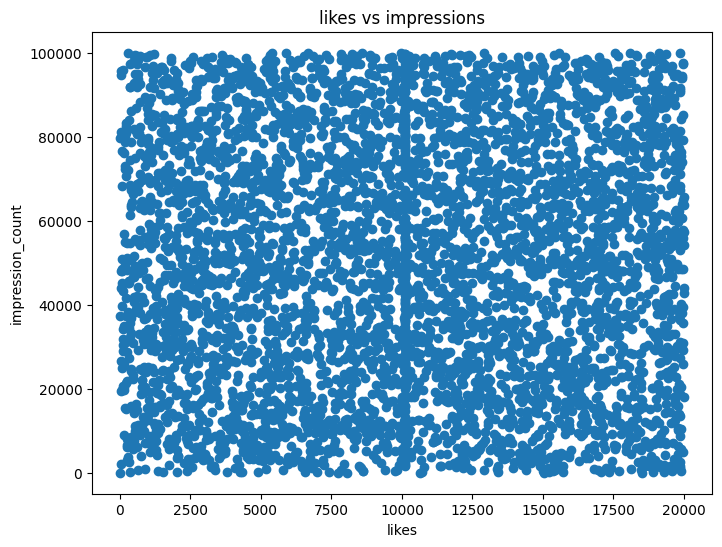

In [58]:
#Scatter: likes vs impressions
import matplotlib.pyplot as plt
plt.figure(figsize=(8,6))
plt.title("likes vs impressions")
plt.scatter(df["likes"],df["impression_count"])
plt.xlabel("likes")
plt.ylabel("impression_count")
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

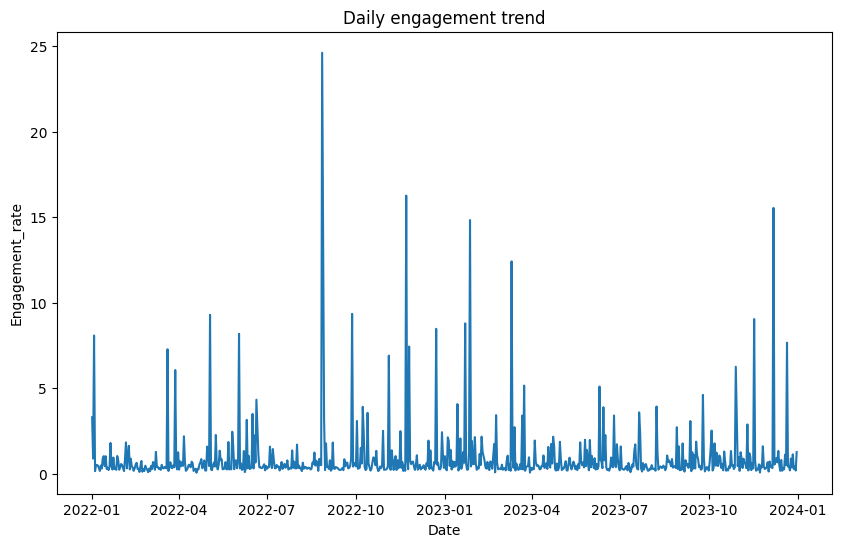

In [59]:
#Line: daily engagement trend
daily_engagement=df.groupby(df["posted_at"].dt.date)["engagement_rate"].mean()
plt.figure(figsize=(10,6))
plt.title("Daily engagement trend")
plt.plot(daily_engagement)
plt.xlabel("Date")
plt.ylabel("Engagement_rate")
plt.show

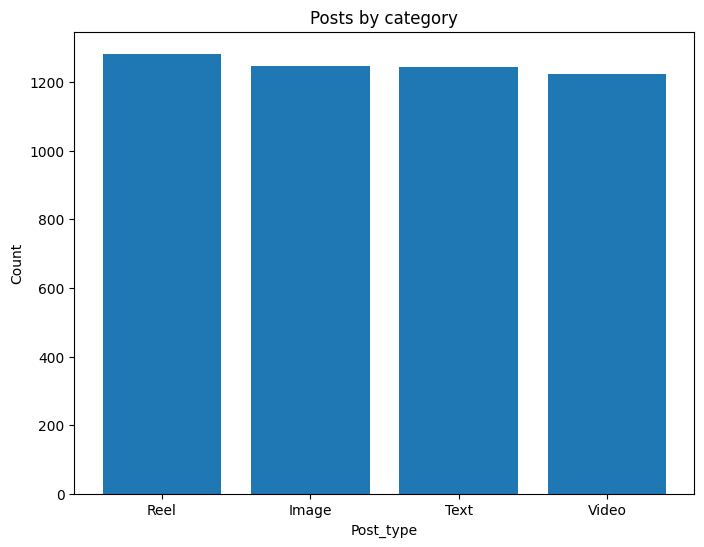

In [60]:
#Bar: posts by category
plt.figure(figsize=(8,6))
plt.title("Posts by category")
plt.bar(df["post_type"].value_counts().index,df["post_type"].value_counts().values)
plt.xlabel("Post_type")
plt.ylabel("Count")
plt.show()

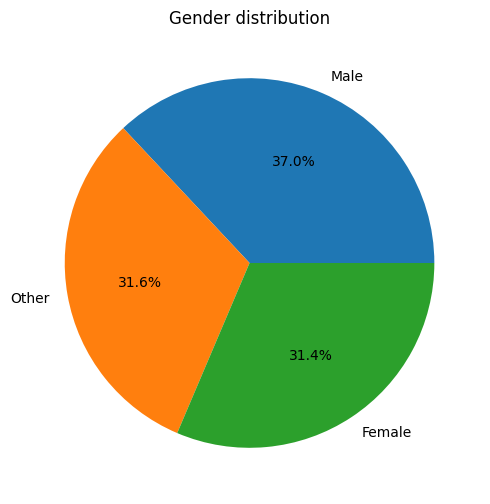

In [61]:
#Pie: gender distribution
plt.figure(figsize=(8,6))
plt.title("Gender distribution")
plt.pie(df["gender"].value_counts(),labels=df["gender"].value_counts().index,autopct="%1.1f%%")
plt.show()

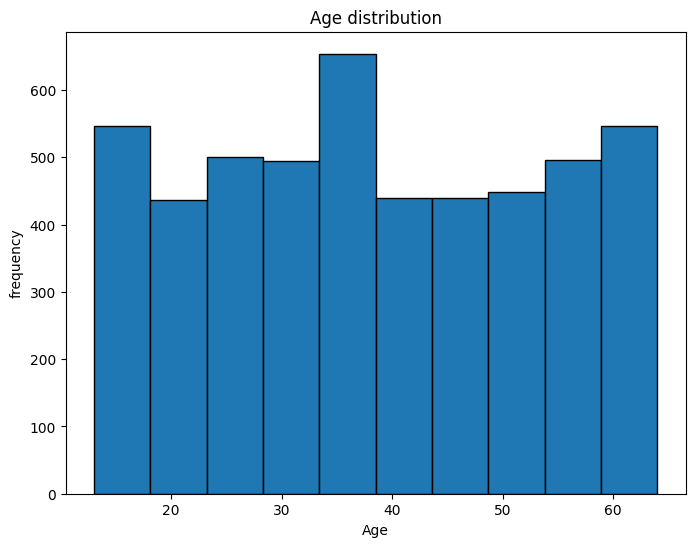

In [62]:
#Histogram: age
plt.figure(figsize=(8,6))
plt.title("Age distribution")
plt.hist(df["age"],bins=10,edgecolor="black")
plt.xlabel("Age")
plt.ylabel("frequency")
plt.show()

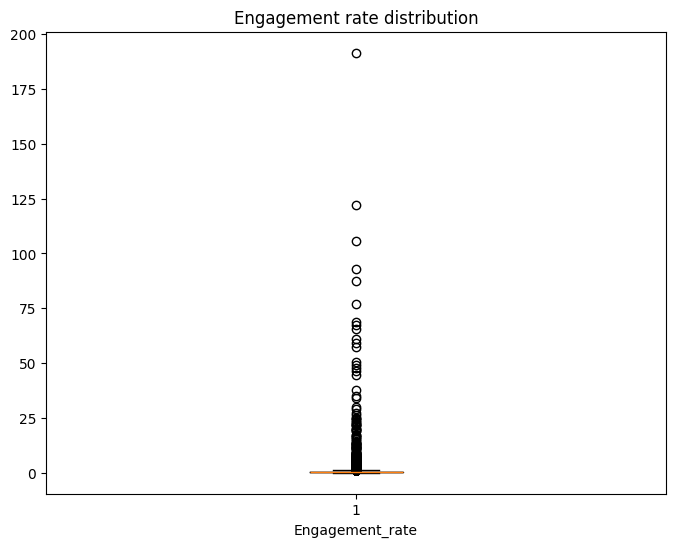

In [63]:
#Box: engagement rate
plt.figure(figsize=(8,6))
plt.title("Engagement rate distribution")
plt.boxplot(df["engagement_rate"])
plt.xlabel("Engagement_rate")
plt.show()

####Seaborn
Count plot: post type
Visualized frequency of different post types. Most occured post_type is reels.

Bar plot: avg likes by category
Compareed average likes across categories. It Shows food content resonates most.

Violin: followers vs sentiment
Displayed distribution of followers by sentiment. Reveals density and spread.

Pair plot: numeric features
Shows relationships between multiple numeric variables (likes, impressions, age, engagement rate).

Heatmap: correlation matrix
Highlights correlations between numeric features. Useful for feature selection.

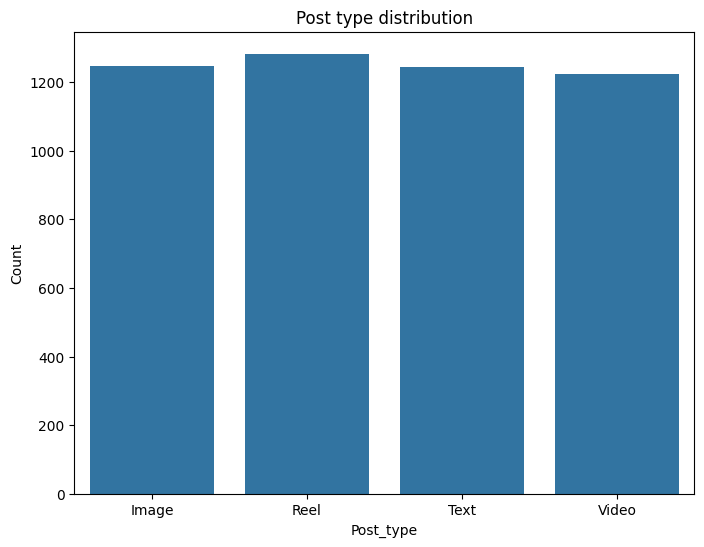

In [64]:
#Count plot: post type
import seaborn as sns
plt.figure(figsize=(8,6))
sns.countplot(data=df,x="post_type")
plt.title("Post type distribution")
plt.xlabel("Post_type")
plt.ylabel("Count")
plt.show()

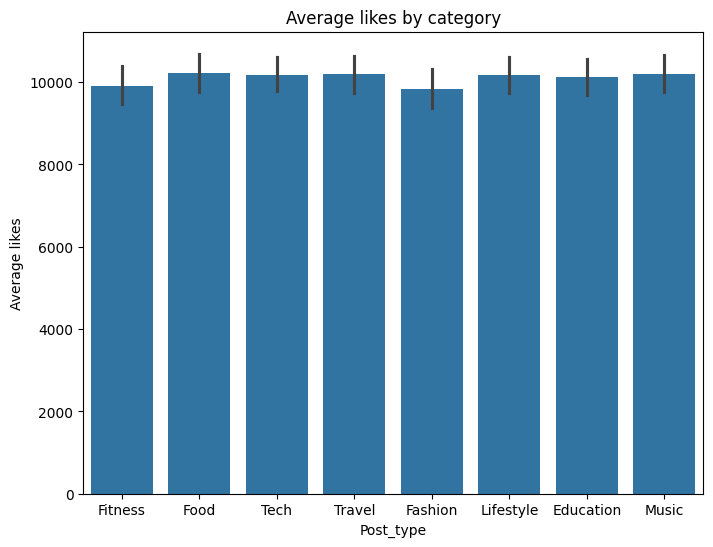

In [65]:
#Bar plot: avg likes by category
plt.figure(figsize=(8,6))
sns.barplot(data=df,x="post_category",y="likes")
plt.title("Average likes by category")
plt.xlabel("Post_type")
plt.ylabel("Average likes")
plt.show()

Text(0, 0.5, 'Followers')

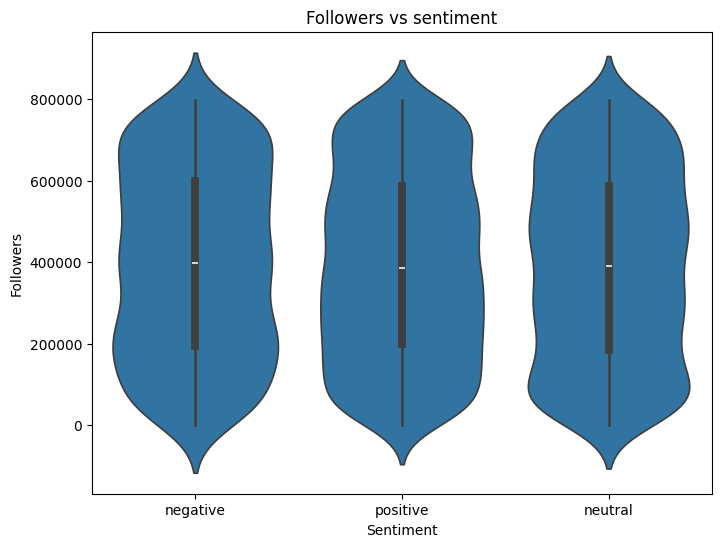

In [58]:
#Violin: followers vs sentiment
plt.figure(figsize=(8,6))
sns.violinplot(data=df,x="sentiment",y="follower_count")
plt.title("Followers vs sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Followers")

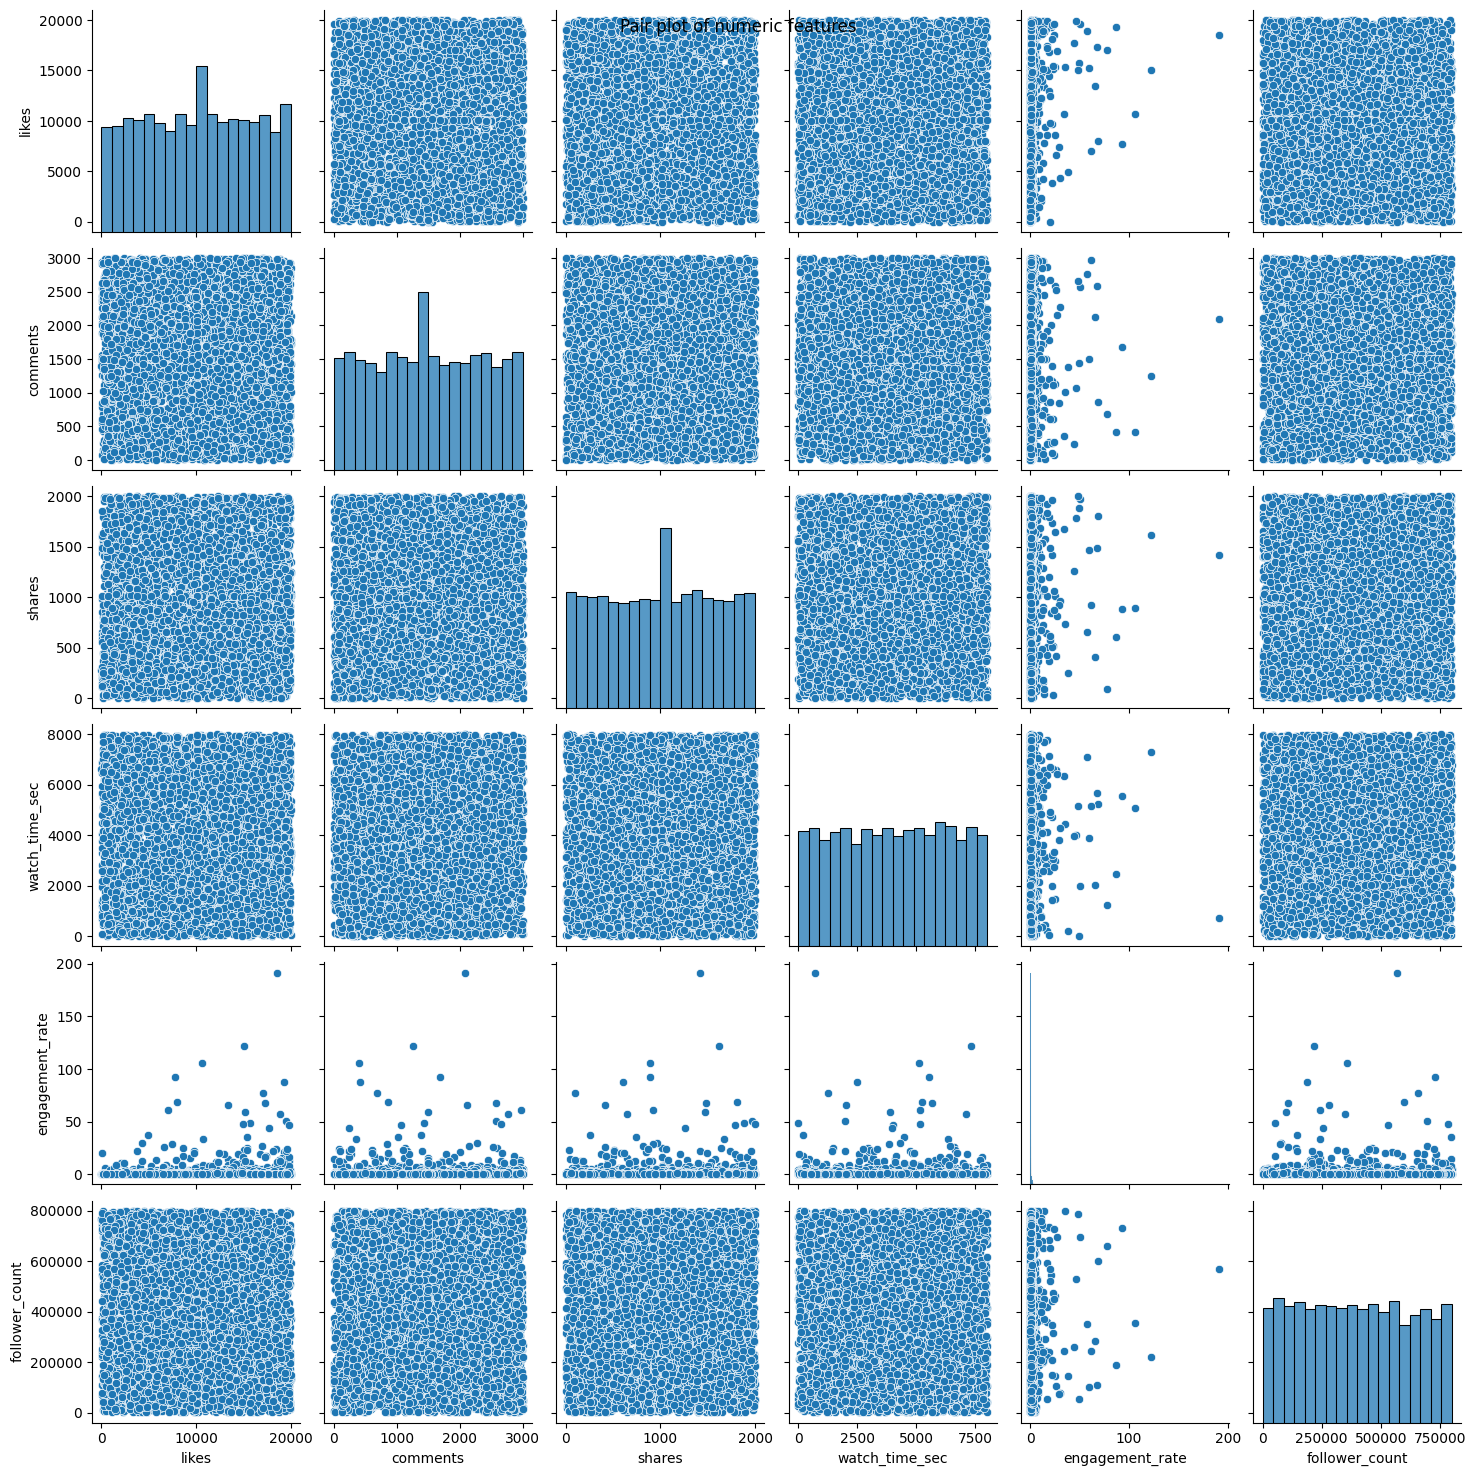

In [59]:
#Pair plot: numeric features
sns.pairplot(df[["likes","comments","shares","watch_time_sec","engagement_rate","follower_count"]])
plt.suptitle("Pair plot of numeric features")
plt.show()

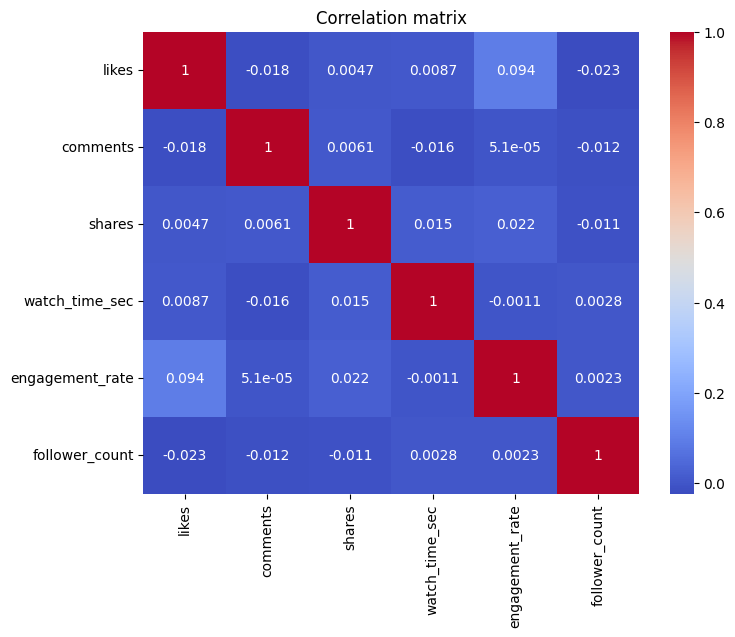

In [66]:
#Heatmap: correlation matrix
correlation_matrix=df[["likes","comments","shares","watch_time_sec","engagement_rate","follower_count"]].corr()
plt.figure(figsize=(8,6))
sns.heatmap(correlation_matrix,annot=True,cmap="coolwarm")
plt.title("Correlation matrix")
plt.show()

####Plotly (Interactive)
Interactive bar chart
Displays which content categories drive higher likes in a dynamic way compared to static charts.

In [70]:
#Interactive bar chart
import plotly.express as px
fig=px.bar(df,x="country",y="engagement_rate",title="Engagement rate by country")
fig.show()

###Final Insights & analysis (Descriptive analysis in MS WORD)

####Content Performance
Used "groupby()" function:
Which post types have highest engagement?

Best-performing content category

Which countries have highest avg engagement rate?

####User Trends

Used "groupby()" function:
How age affects engagement

Performance difference for verified accounts


####Behavioral Insights
Used "groupby()" function:
Best time of day for impressions


Device type impact on watch time


####Sentiment Analysis
Used "groupby()" function:
Which sentiment performs best

Behavior of negative/neutral sentiment posts


In [47]:
#Best-performing content category
df.groupby("post_category")["engagement_rate"].mean().round(3).sort_values(ascending=False)


,engagement_rate
post_category,
Food,1.359
Tech,1.160
Lifestyle,1.091
Music,0.889
Fitness,0.866
Education,0.844
Fashion,0.807
Travel,0.702


In [48]:
#country by average engagement rate
df.groupby("country")["engagement_rate"].mean().round(3).sort_values(ascending=False)

,engagement_rate
country,
Brazil,1.541
Australia,1.324
France,1.146
UAE,1.112
Canada,0.917
UK,0.851
Japan,0.770
Germany,0.759
India,0.655


In [49]:
#How age affects engagement?
df.groupby("age")["engagement_rate"].mean().round(3).sort_values(ascending=False)


,engagement_rate
age,
24,2.897
55,2.599
51,2.397
48,1.676
50,1.553
41,1.540
35,1.522
47,1.402
42,1.351


In [50]:
#Performance difference for verified accounts
df.groupby("is_verified")["engagement_rate"].mean().round(3).sort_values(ascending=False)

,engagement_rate
is_verified,
True,1.054
False,0.955


In [51]:
#Best time of day for impressions, checking for time
df["posted_at"].head().dt.strftime("%y-%m-%d %H:%M:%S")


,posted_at
0,22-12-17 00:00:00
1,23-06-02 00:00:00
2,23-05-07 00:00:00
3,23-02-12 00:00:00
4,23-05-23 00:00:00


In [52]:
#Device type impact on watch time
df.groupby("device_type")["watch_time_sec"].mean().round(3).sort_values(ascending=False)

,watch_time_sec
device_type,
Mobile,4087.831
Tablet,3979.736
Desktop,3974.793


In [53]:
#Which sentiment performs best
df.groupby("sentiment")["engagement_rate"].mean().round(3).sort_values(ascending=False)

,engagement_rate
sentiment,
Negative,1.015
Neutral,0.974
Positive,0.938


In [56]:
#Behavior of negative/neutral sentiment posts
df[df["sentiment"].isin(["Negative","Neutral"])].groupby("sentiment")["engagement_rate"].describe().round(3)


,count,mean,std,min,25%,50%,75%,max
sentiment,,,,,,,,
Negative,991.0,1.015,4.598,0.020,0.150,0.252,0.475,68.686
Neutral,1575.0,0.974,5.308,0.007,0.147,0.253,0.529,121.932
